In [9]:
import stim
import numpy as np
import pymatching
import matplotlib.pyplot as plt
import sinter
from typing import List
import os
import time

Starting 24 workers...
10 tasks left:
  workers    decoder eta shots_left errors_left json_metadata   
        3 pymatching   ?    1000000        5000 d=3,r=9,p=0.008 
        3 pymatching <1m     999727        4969 d=5,r=15,p=0.008
        3 pymatching   ?    1000000        5000 d=3,r=9,p=0.009 
        3 pymatching   ?    1000000        5000 d=5,r=15,p=0.009
        2 pymatching   ?    1000000        5000 d=3,r=9,p=0.01  
        2 pymatching   ?    1000000        5000 d=5,r=15,p=0.01 
        2 pymatching   ?    1000000        5000 d=3,r=9,p=0.011 
        2 pymatching   ?    1000000        5000 d=5,r=15,p=0.011
        2 pymatching   ?    1000000        5000 d=3,r=9,p=0.012 
        2 pymatching   ?    1000000        5000 d=5,r=15,p=0.012
10 tasks left:
  workers    decoder eta shots_left errors_left json_metadata   
        3 pymatching <1m     979247        2803 d=3,r=9,p=0.008 
        3 pymatching <1m     996382        4488 d=5,r=15,p=0.008
        3 pymatching <1m     990511  

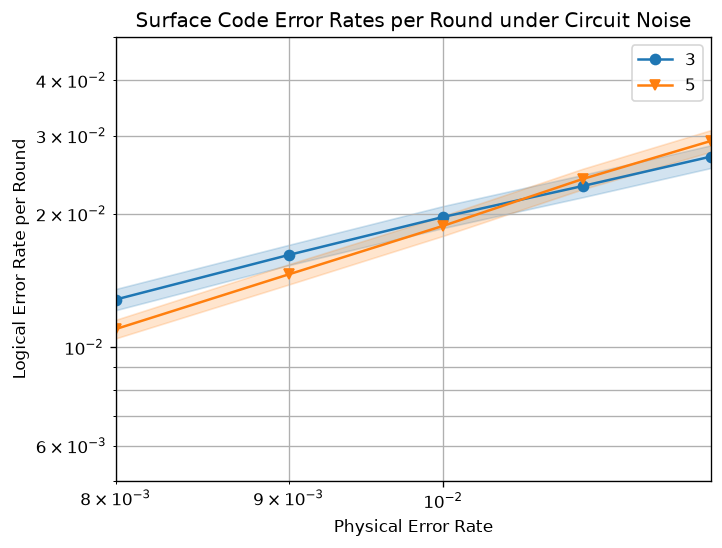

: 

In [ ]:
def make_circuit(p: float, d: int, r: int) -> stim.Circuit:
    """Create circuit given the probability of error, the distance and the number of rounds"""
    return stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        rounds=r,
        distance=d,
        after_clifford_depolarization=p,
        after_reset_flip_probability=p,
        before_measure_flip_probability=p,
        before_round_data_depolarization=p,
        )
    
    
def make_dataset(circuit: stim.Circuit, num_shots: int, seed: int = 4321) -> tuple[np.ndarray, np.ndarray]:
    """Compile circuit and extract the results"""
    sampler = circuit.compile_detector_sampler(seed=seed)
    detection_events, observable_flips = sampler.sample(num_shots, separate_observables=True)
    return detection_events, observable_flips


def save_dataset(detection_events: np.ndarray, observable_flips: np.ndarray, filename: str) -> None:
    """Save detection events and observable flips to a compressed .npz file."""
    np.savez_compressed(filename, dets=detection_events, obs=observable_flips)
    
    
def load_dataset(filename: str) -> tuple[np.ndarray, np.ndarray]:
    """Load detection events and observable flips from a .npz file."""
    data = np.load(filename)
    return data["dets"], data["obs"]


def pymatching_decoder(circuit: stim.Circuit, detection_events: np.ndarray) -> tuple[np.ndarray, float]:
    # Configure the pymatching decoder for the given circuit.
    detector_error_model = circuit.detector_error_model(decompose_errors=True)
    matcher = pymatching.Matching.from_detector_error_model(detector_error_model)

    # Run the pymatching decoder.
    start = time.perf_counter()
    predictions = matcher.decode_batch(detection_events)
    end = time.perf_counter()
    
    total_time = (end - start) # time in seconds
    
    return predictions, total_time


def count_logical_errors(observable_flips, predictions) -> int:
    # Count and return the mistakes.
    return int(np.sum(np.any(observable_flips != predictions, axis=1)))


def _plot_error_rate(collected_surface_code_stats):
    fig, ax = plt.subplots(1, 1)
    sinter.plot_error_rate(
        ax=ax,
        stats=collected_surface_code_stats,
        x_func=lambda stat: stat.json_metadata['p'],
        group_func=lambda stat: stat.json_metadata['d'],
        failure_units_per_shot_func=lambda stat: stat.json_metadata['r'],
    )

    ax.set_ylim(5e-3, 5e-2)
    ax.set_xlim(0.008, 0.012)
    ax.loglog()
    ax.set_title("Surface Code Error Rates per Round under Circuit Noise")
    ax.set_xlabel("Physical Error Rate")
    ax.set_ylabel("Logical Error Rate per Round")
    ax.grid(which='major')
    ax.grid(which='minor')
    ax.legend()
    fig.set_dpi(120)
    fig.savefig("threshold.png")


if __name__ == "__main__":
    surface_code_tasks = [
        sinter.Task(
            circuit = make_circuit(noise, d, 3*d),
            json_metadata={'d': d, 'r': 3*d, 'p': noise},
        )
        for noise in [0.008, 0.009, 0.01, 0.011, 0.012]
        for d in [3,5]
    ]

    collected_surface_code_stats: List[sinter.TaskStats] = sinter.collect(
        num_workers=os.cpu_count(),
        tasks=surface_code_tasks,
        decoders=['pymatching'],
        max_shots=1_000_000,
        max_errors=5_000,
        print_progress=True,
    )
    
    _plot_error_rate(collected_surface_code_stats)
